In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import string
import nltk

data = pd.read_csv(
    "../data/SMSSpamCollection",
    sep="\t",
    header=None,
    names=["label", "message"]
)
data['message'] = data['message'].str.lower()
translator = str.maketrans('', '', string.punctuation)

data['cleaned_message'] = data['message'].apply(
    lambda x: x.translate(translator)
)



In [5]:
from nltk.corpus import stopwords

stop_words = stopwords.words('english')

print('not' in stop_words)
print('no' in stop_words)

True
True


In [6]:
stop_words = set(stopwords.words('english'))

stop_words.remove('not')
stop_words.remove('no')

print('not' in stop_words)
print('no' in stop_words)

False
False


In [7]:
nltk.download('punkt_tab')

[nltk_data] Downloading package punkt_tab to
[nltk_data]     /home/rapheal/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [8]:
from nltk.tokenize import word_tokenize
message = data['cleaned_message'][0]

tokens = word_tokenize(message)

filtered_tokens = [word for word in tokens if word not in stop_words]
print(filtered_tokens)

['go', 'jurong', 'point', 'crazy', 'available', 'bugis', 'n', 'great', 'world', 'la', 'e', 'buffet', 'cine', 'got', 'amore', 'wat']


In [9]:
def remove_stopwords(text):
    tokens = word_tokenize(text)
    filtered_tokens = [word for word in tokens if word not in stop_words]
    return filtered_tokens



data['filtered_message'] = data['cleaned_message'].apply(remove_stopwords)
data[['cleaned_message', 'filtered_message']].head()

,cleaned_message,filtered_message
0,go until jurong point crazy available only in ...,"[go, jurong, point, crazy, available, bugis, n..."
1,ok lar joking wif u oni,"[ok, lar, joking, wif, u, oni]"
2,free entry in 2 a wkly comp to win fa cup fina...,"[free, entry, 2, wkly, comp, win, fa, cup, fin..."
3,u dun say so early hor u c already then say,"[u, dun, say, early, hor, u, c, already, say]"
4,nah i dont think he goes to usf he lives aroun...,"[nah, dont, think, goes, usf, lives, around, t..."


In [10]:
from collections import Counter
all_words = []

for message in data['filtered_message']:
    all_words.extend(message)

word_counts = Counter(all_words)
word_counts.most_common(10)

[('u', 1133),
 ('call', 578),
 ('2', 482),
 ('im', 464),
 ('not', 441),
 ('ur', 390),
 ('get', 386),
 ('no', 334),
 ('4', 293),
 ('dont', 287)]

In [11]:
spam_messages = data[data['label'] == 'spam']

spam_words = []

for message in spam_messages['filtered_message']:
    spam_words.extend(message)

spam_word_counts = Counter(spam_words)

spam_word_counts.most_common(10)

[('call', 347),
 ('free', 216),
 ('2', 173),
 ('txt', 150),
 ('u', 148),
 ('ur', 144),
 ('mobile', 123),
 ('text', 120),
 ('4', 119),
 ('stop', 115)]

In [12]:
ham_messages = data[data['label'] == 'ham']

ham_words = []

for message in ham_messages['filtered_message']:
    ham_words.extend(message)

ham_word_counts = Counter(ham_words)

ham_word_counts.most_common(10)

[('u', 985),
 ('im', 451),
 ('not', 417),
 ('2', 309),
 ('get', 303),
 ('ltgt', 276),
 ('no', 274),
 ('ok', 273),
 ('dont', 265),
 ('go', 250)]

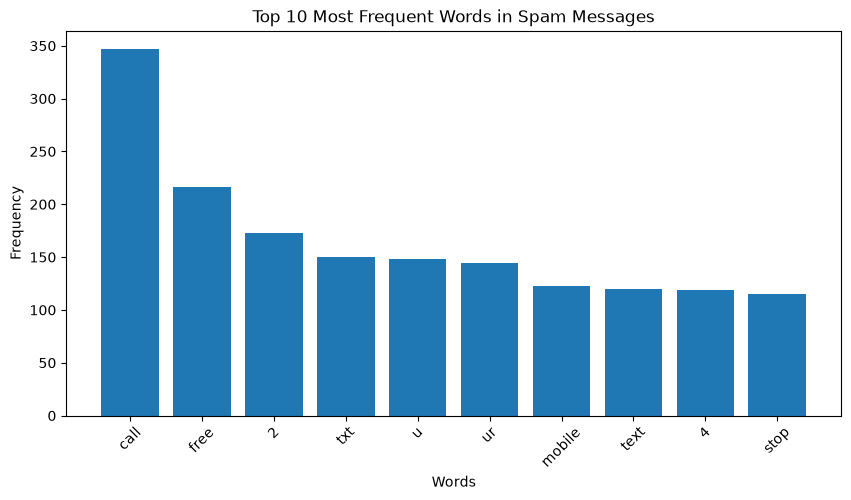

In [13]:
top_spam_words = spam_word_counts.most_common(10)

words = [item[0] for item in top_spam_words]
frequencies = [item[1] for item in top_spam_words]

plt.figure(figsize=(10, 5))
plt.bar(words, frequencies)
plt.title("Top 10 Most Frequent Words in Spam Messages")
plt.xlabel("Words")
plt.ylabel("Frequency")
plt.xticks(rotation=45)
plt.show()

In [20]:
import os
data.to_csv("../data/cleaned_sms.csv", index=False)
print(os.listdir("../data"))

['SMSSpamCollection', 'cleaned_sms.csv']


In [17]:
import string

print(data['cleaned_message'].str.contains(
    '[' + string.punctuation + ']',
    regex=True
).sum())

0


In [21]:
import os
print(os.path.exists("../data/cleaned_sms.csv"))

True
